<a href="https://colab.research.google.com/github/julianovale/6Sigma/blob/main/01_Seis_Sigma_com_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estatística para Seis Sigma utilizando o Python





## 1. Apresentação
---


Projetos Seis Sigma são tradicionalmente desenvolvidos por meio do método DMAIC, composto pelas etapas **Define (Definir)**, **Measure (Medir)**, **Analyze (Analisar)**, **Improve (Melhorar)** e **Control (Controlar)**. Em cada uma dessas fases são empregadas ferramentas estatísticas com diferentes objetivos: compreender o comportamento dos processos, identificar causas de problemas, validar hipóteses, propor melhorias e sustentar os resultados obtidos.

O objetivo deste material não é apresentar a metodologia Seis Sigma em profundidade nem substituir os programas de formação Green Belt ou Black Belt. Existe vasta bibliografia dedicada a esse propósito. A proposta deste trabalho é mais específica: apresentar os principais conceitos estatísticos utilizados em projetos Seis Sigma, contextualizando-os dentro das etapas do DMAIC e demonstrando sua implementação por meio da linguagem Python.

A escolha do Python justifica-se pela escassez de material didático de qualidade que integre Seis Sigma e programação. Grande parte da literatura e dos treinamentos disponíveis apoia-se em softwares estatísticos proprietários, especialmente o Minitab. Embora esses softwares sejam amplamente utilizados e possuam inegável relevância profissional, o Python oferece uma alternativa gratuita, flexível, reproduzível e cientificamente robusta para a realização das mesmas análises.

Além disso, a linguagem vem se consolidando como uma das principais ferramentas de análise de dados, ciência de dados e aprendizado de máquina, permitindo que profissionais da qualidade, engenheiros e pesquisadores integrem técnicas estatísticas clássicas com abordagens modernas de análise.

Ao longo deste material serão utilizadas bibliotecas consolidadas do ecossistema científico do Python, entre elas:

- **NumPy**: computação numérica e vetorial;
- **Pandas**: manipulação e tratamento de dados;
- **SciPy**: testes estatísticos e métodos científicos;
- **StatsModels**: modelagem estatística;
- **Matplotlib** e **Seaborn**: visualização gráfica;
- **Scikit-Learn**: mineração de dados e aprendizado de máquina.

Os códigos desenvolvidos durante esta jornada poderão ser adaptados para diferentes tipos de projetos Seis Sigma, servindo tanto como material de estudo quanto como base para aplicações práticas em ambientes industriais, logísticos, financeiros e de serviços.

Por fim, este material parte de uma visão que considero fundamental para a Engenharia e para a melhoria de processos:

> Um bom modelo não é aquele que representa toda a realidade, mas aquele que representa os aspectos mais importantes da realidade com simplicidade suficiente para permitir decisões melhores.

Assim, mais do que reproduzir procedimentos estatísticos ou funcionalidades de softwares específicos, o foco será compreender os conceitos, interpretar corretamente os resultados e construir soluções reproduzíveis, transparentes e aplicáveis a problemas reais.

## 2. Etapa "Definir"
---
Embora a estatística seja formalmente mais explorada nas etapas Measure e Analyze, algumas ferramentas estatísticas podem ser utilizadas já na fase Define para caracterizar o problema, quantificar sua magnitude e justificar a relevância do projeto.

Ferramentas frequentemente utilizadas nesta etapa incluem:

- Estatística descritiva;
- Histogramas e Boxplots;
- Análise temporal;
- Indicadores de desempenho;
- Cartas de controle (quando existirem dados históricos suficientes);
- Análise preliminar de capabilidade;
- Testes de normalidade (quando necessários para análises subsequentes).

### 2.1 Caso de Estudo: Processo de Envase de Refrigerantes

Para ilustrar os conceitos estatísticos apresentados ao longo deste material, será utilizado um único caso de estudo ao longo de todas as etapas do método DMAIC.

A empresa analisada produz refrigerantes em garrafas com volume nominal de 290 ml. Por requisitos internos da qualidade e especificações de engenharia do produto, adotam-se os seguintes limites de especificação:

- Limite Inferior de Especificação (LIE): 285 ml;
- Valor Alvo (Target): 290 ml;
- Limite Superior de Especificação (LSE): 295 ml.

Nos últimos meses foram registradas reclamações relacionadas à consistência do volume envasado. Embora não existam evidências conclusivas sobre a magnitude e a origem do problema, a percepção dos responsáveis pelo processo é que podem existir desvios sistemáticos no enchimento das garrafas.

Diante desse cenário, um projeto Seis Sigma foi iniciado com o objetivo de compreender o comportamento do processo de envase e verificar se existem oportunidades de melhoria.

Ao longo deste material serão utilizados dados simulados desse processo para exemplificar a aplicação das principais ferramentas estatísticas em Python. A partir desses dados procuraremos responder perguntas típicas de um projeto DMAIC:

- O problema realmente existe?
- O processo é estável?
- Os dados seguem distribuição normal?
- O processo atende às especificações definidas pela engenharia?
- Existe deslocamento em relação ao valor-alvo?
- Existem causas especiais de variação?
- Quais ações poderiam melhorar o desempenho do processo?
- Como garantir a sustentação dos resultados obtidos?

Os mesmos dados serão utilizados em diferentes capítulos para demonstrar conceitos de estatística descritiva, visualização de dados, análise de normalidade, controle estatístico de processos, capabilidade, testes de hipóteses, regressão, simulação e outras ferramentas usualmente empregadas em projetos Seis Sigma.

          QUADRO DE ESTATÍSTICA DESCRITIVA DA AMOSTRA          
Tamanho da Amostra (n):     60
Média (x̄):                 292.875 ml
Mediana:                    292.700 ml
Desvio Padrão (s):          1.909 ml
Variância (s²):             3.643
Mínimo / Máximo:            289.10 ml / 297.10 ml
Amplitude Total (R):        8.00 ml
Intervalo Interquartil (IQR):2.275 ml
Assimetria (Skewness):      0.026
Curtose (Kurtosis):         -0.454
------------------------------------------------------------
TESTE DE NORMALIDADE (Shapiro-Wilk):
Estatística W:              0.9875
p-valor:                    0.7989
Conclusão: p-valor >= 0.05 -> Os dados SEGUEM uma Distribuição Normal (95% de confiança).


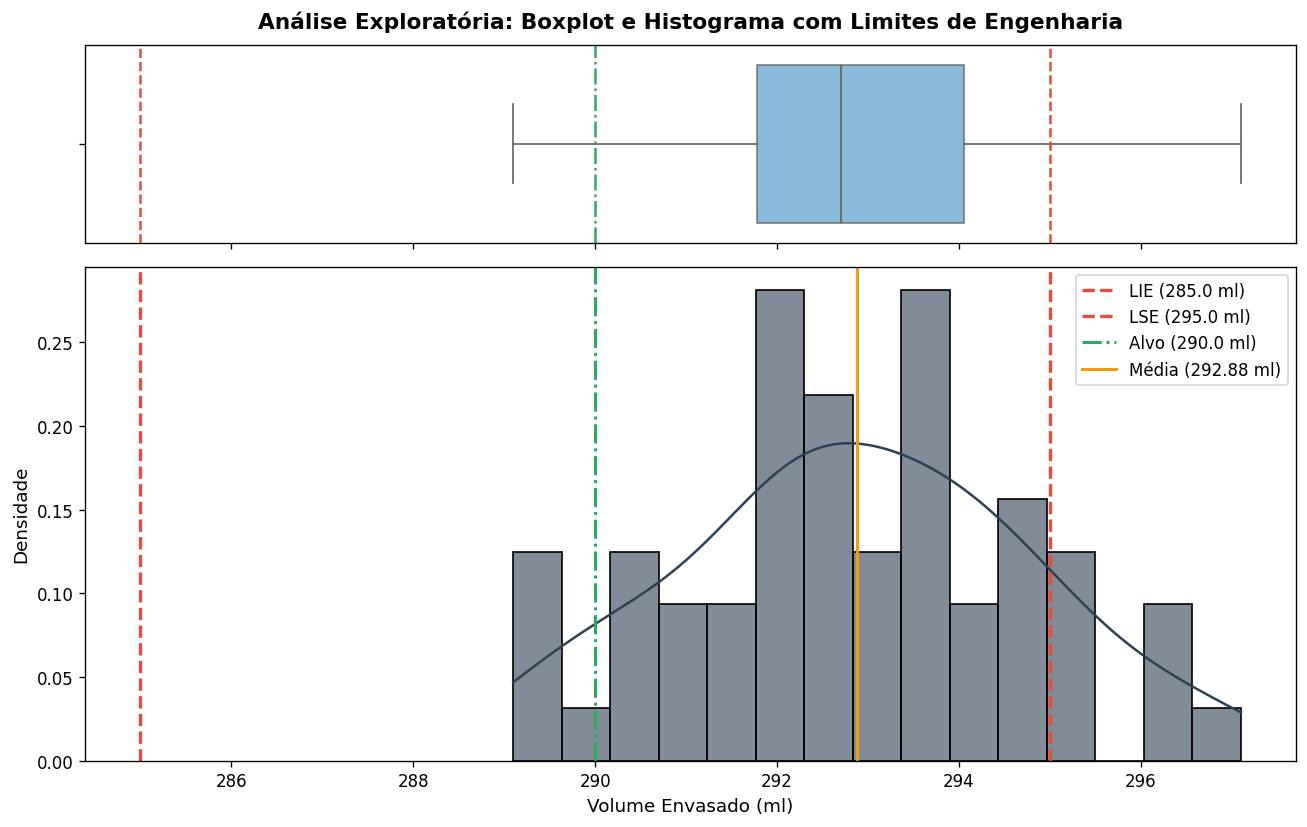

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Carregamento dos dados
url_raw = "https://raw.githubusercontent.com/julianovale/6Sigma/main/Base/Envase.csv"
df = pd.read_csv(url_raw)
vol = df["volume_ml"]

# Parâmetros de Engenharia
LIE, LSE, ALVO = 285.0, 295.0, 290.0

# 2. Quadro de Estatísticas Descritivas Completas
desc = vol.describe()
assimetria = vol.skew()
curtose = vol.kurtosis()
iqr = desc["75%"] - desc["25%"]

print("="*60)
print("          QUADRO DE ESTATÍSTICA DESCRITIVA DA AMOSTRA          ")
print("="*60)
print(f"Tamanho da Amostra (n):     {int(desc['count'])}")
print(f"Média (x̄):                 {desc['mean']:.3f} ml")
print(f"Mediana:                    {desc['50%']:.3f} ml")
print(f"Desvio Padrão (s):          {desc['std']:.3f} ml")
print(f"Variância (s²):             {vol.var():.3f}")
print(f"Mínimo / Máximo:            {desc['min']:.2f} ml / {desc['max']:.2f} ml")
print(f"Amplitude Total (R):        {desc['max'] - desc['min']:.2f} ml")
print(f"Intervalo Interquartil (IQR):{iqr:.3f} ml")
print(f"Assimetria (Skewness):      {assimetria:.3f}")
print(f"Curtose (Kurtosis):         {curtose:.3f}")
print("-" * 60)

# 3. Teste de Normalidade de Shapiro-Wilk
stat_shapiro, p_val_shapiro = stats.shapiro(vol)

print("TESTE DE NORMALIDADE (Shapiro-Wilk):")
print(f"Estatística W:              {stat_shapiro:.4f}")
print(f"p-valor:                    {p_val_shapiro:.4f}")

if p_val_shapiro >= 0.05:
    print("Conclusão: p-valor >= 0.05 -> Os dados SEGUEM uma Distribuição Normal (95% de confiança).")
else:
    print("Conclusão: p-valor < 0.05 -> Os dados NÃO seguem uma Distribuição Normal.")
print("="*60)

# 4. Construção da Figura (Boxplot Horizontal + Histograma com Limites)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2.5]}, dpi=120)

# Visualização 1: Boxplot
sns.boxplot(x=vol, ax=axes[0], color="#5DADE2", fliersize=5, boxprops=dict(alpha=0.8))
axes[0].set(xlabel='')
axes[0].set_title("Análise Exploratória: Boxplot e Histograma com Limites de Engenharia", fontsize=13, fontweight='bold', pad=10)
axes[0].axvline(LIE, color="#E74C3C", linestyle="--", linewidth=1.5)
axes[0].axvline(LSE, color="#E74C3C", linestyle="--", linewidth=1.5)
axes[0].axvline(ALVO, color="#27AE60", linestyle="-.", linewidth=1.5)

# Visualização 2: Histograma com KDE
sns.histplot(vol, kde=True, ax=axes[1], color="#2E4053", bins=15, stat="density", alpha=0.6)
axes[1].axvline(LIE, color="#E74C3C", linestyle="--", linewidth=2, label=f"LIE ({LIE} ml)")
axes[1].axvline(LSE, color="#E74C3C", linestyle="--", linewidth=2, label=f"LSE ({LSE} ml)")
axes[1].axvline(ALVO, color="#27AE60", linestyle="-.", linewidth=1.8, label=f"Alvo ({ALVO} ml)")
axes[1].axvline(desc['mean'], color="#F39C12", linestyle="-", linewidth=1.8, label=f"Média ({desc['mean']:.2f} ml)")

axes[1].set_xlabel("Volume Envasado (ml)", fontsize=11)
axes[1].set_ylabel("Densidade", fontsize=11)
axes[1].legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()